# Uji Validitas dan Reliabilitas Kuesioner

Kuesioner versi baru, 29 butir (data kelas 3 TI A)  
Mata kuliah Statistika Probabilitas  
Nama  : David Geraldo Joshua Siagian  
NIM   : 2455301043  
Kelas : 3 TI A  
Langkah-langkah program mengikuti modul  
"Pengujian Validitas dan Reliabilitas Instrumen".

## Langkah 1 - Import library

In [1]:
import os

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib

matplotlib.use("Agg")  # supaya grafik langsung disimpan ke file
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

FILE_DATA = "data/Respons Gabungan 3 TI A - Versi Baru - 29 Butir.xlsx"
FOLDER_OUTPUT = "output"
os.makedirs(FOLDER_OUTPUT, exist_ok=True)

## Langkah 2 - Baca data

In [2]:
df = pd.read_excel(FILE_DATA)
df = df.rename(columns={"Cap waktu": "Timestamp"})  # samakan nama kolom waktu
print("Jumlah responden:", len(df))
print("Kelas:", df["Kelas"].unique())

Jumlah responden: 39
Kelas: <StringArray>
['3 TI A']
Length: 1, dtype: str


## Langkah 3 - Ambil kolom butir

In [3]:
# Judul kolom butir bentuknya "Nama dimensi [KODE. pernyataan]".
# Kolom lain (Cap waktu dan Kelas) tidak ikut diuji.
kolom_butir = []
for kolom in df.columns:
    if "[" in kolom and "]" in kolom:
        kolom_butir.append(kolom)

print("Jumlah butir:", len(kolom_butir))

Jumlah butir: 29


## Langkah 4 - Ubah jawaban menjadi angka

In [4]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}

data = pd.DataFrame()
for kolom in kolom_butir:
    data[kolom] = df[kolom].astype(str).str.strip().map(skala)

print("Jawaban kosong / gagal diubah:", data.isna().sum().sum())  # harus 0

Jawaban kosong / gagal diubah: 0


## Langkah 5 - Kelompokkan butir per dimensi

In [5]:
# Contoh judul kolom:
#   "Prokrastinasi akademik [PA1. Saya menunda memulai tugas kuliah ...]"
# Dari judul itu diambil:
#   nama dimensi = Prokrastinasi akademik
#   kode butir   = PA1
#   pernyataan   = Saya menunda memulai tugas kuliah ...
dimensi = {}      # nama dimensi -> daftar kode butir
pernyataan = {}   # kode butir -> isi pernyataan
nama_baru = {}    # judul kolom asli -> kode butir

for kolom in kolom_butir:
    nama_dimensi = kolom.split("[")[0].strip()
    nama_dimensi = nama_dimensi[0].upper() + nama_dimensi[1:]  # huruf pertama kapital
    isi = kolom.split("[")[1].replace("]", "").strip()
    kode = isi.split(".")[0]
    teks = isi[len(kode) + 1:].strip()

    if nama_dimensi not in dimensi:
        dimensi[nama_dimensi] = []
    dimensi[nama_dimensi].append(kode)
    pernyataan[kode] = teks
    nama_baru[kolom] = kode

# kolom data diganti dengan kode butir supaya lebih pendek
data = data.rename(columns=nama_baru)

for nama_dimensi, daftar_kode in dimensi.items():
    print(nama_dimensi, ":", daftar_kode)

print(data.head())

Penggunaan AI pada tugas atau projek kuliah : ['AI1', 'AI2', 'AI3', 'AI4', 'AI5', 'AI6', 'AI7']
Aspek psikologis penggunaan AI pada tugas atau projek kuliah : ['PS1', 'PS2', 'PS3', 'PS4', 'PS5', 'PS6', 'PS7']
Kebiasaan penggunaan teknologi digital : ['TD1', 'TD2', 'TD3', 'TD4', 'TD5', 'TD6']
Prokrastinasi akademik : ['PA1', 'PA2', 'PA3', 'PA4']
Respons emosional : ['RE1', 'RE2', 'RE3', 'RE4', 'RE5']
   AI1  AI2  AI3  AI4  AI5  AI6  AI7  PS1  PS2  PS3  ...  TD6  PA1  PA2  PA3  \
0    1    2    4    5    4    2    1    1    2    4  ...    2    1    2    4   
1    1    2    1    5    5    4    1    1    2    1  ...    1    4    4    4   
2    1    2    1    2    2    2    1    2    2    1  ...    2    1    2    2   
3    5    4    2    1    2    4    5    1    2    4  ...    5    1    2    5   
4    5    4    2    1    2    4    5    5    4    2  ...    4    5    4    2   

   PA4  RE1  RE2  RE3  RE4  RE5  
0    5    1    2    4    5    4  
1    1    5    1    1    5    4  
2    1    1   

## Langkah 6 - Uji validitas

In [6]:
# r hitung = korelasi Pearson antara skor butir dan skor total dimensinya.
# r tabel  = batas minimal, dicari dari nilai t (alpha 0,05 dua sisi, df = n - 2).
# Butir valid kalau r hitung > r tabel.
n = len(data)
df_bebas = n - 2
t_tabel = stats.t.ppf(1 - 0.05 / 2, df_bebas)
r_tabel = t_tabel / np.sqrt(df_bebas + t_tabel ** 2)
print(f"n = {n}, df = {df_bebas}, t tabel = {t_tabel:.3f}, r tabel = {r_tabel:.3f}")

hasil_validitas = []
for nama_dimensi, daftar_kode in dimensi.items():
    skor_total = data[daftar_kode].sum(axis=1)
    for kode in daftar_kode:
        r_hitung, p_value = stats.pearsonr(data[kode], skor_total)
        if r_hitung > r_tabel:
            keterangan = "Valid"
        else:
            keterangan = "Tidak valid"
        hasil_validitas.append([nama_dimensi, kode, round(r_hitung, 3), round(r_tabel, 3),
                                round(p_value, 4), keterangan])

tabel_validitas = pd.DataFrame(hasil_validitas, columns=[
    "Dimensi", "Butir", "r hitung", "r tabel", "p-value", "Keterangan"])
print(tabel_validitas.to_string(index=False))

jumlah_valid = (tabel_validitas["Keterangan"] == "Valid").sum()
print(f"Butir valid: {jumlah_valid} dari {len(tabel_validitas)}")

n = 39, df = 37, t tabel = 2.026, r tabel = 0.316
                                                     Dimensi Butir  r hitung  r tabel  p-value  Keterangan
                 Penggunaan AI pada tugas atau projek kuliah   AI1     0.662    0.316   0.0000       Valid
                 Penggunaan AI pada tugas atau projek kuliah   AI2     0.514    0.316   0.0008       Valid
                 Penggunaan AI pada tugas atau projek kuliah   AI3     0.678    0.316   0.0000       Valid
                 Penggunaan AI pada tugas atau projek kuliah   AI4     0.238    0.316   0.1454 Tidak valid
                 Penggunaan AI pada tugas atau projek kuliah   AI5     0.539    0.316   0.0004       Valid
                 Penggunaan AI pada tugas atau projek kuliah   AI6     0.493    0.316   0.0014       Valid
                 Penggunaan AI pada tugas atau projek kuliah   AI7     0.776    0.316   0.0000       Valid
Aspek psikologis penggunaan AI pada tugas atau projek kuliah   PS1     0.494    0.316   0.0014

## Langkah 7 - Uji reliabilitas (Cronbach's Alpha)

In [7]:
def cronbach_alpha(tabel):
    k = tabel.shape[1]                              # jumlah butir
    jumlah_varians_butir = tabel.var(ddof=1).sum()  # varians tiap butir lalu dijumlah
    varians_total = tabel.sum(axis=1).var(ddof=1)   # varians skor total
    return (k / (k - 1)) * (1 - jumlah_varians_butir / varians_total)


def kategori_alpha(alpha):
    if alpha >= 0.90:
        return "Sangat baik"
    elif alpha >= 0.80:
        return "Baik"
    elif alpha >= 0.70:
        return "Reliabel"
    else:
        return "Tidak reliabel"


hasil_reliabilitas = []
alpha_dimensi = {}        # nama dimensi -> nilai alpha
alpha_jika_dihapus = {}   # kode butir -> alpha kalau butir itu dibuang

for nama_dimensi, daftar_kode in dimensi.items():
    alpha = cronbach_alpha(data[daftar_kode])
    alpha_dimensi[nama_dimensi] = round(alpha, 3)
    hasil_reliabilitas.append([nama_dimensi, len(daftar_kode), round(alpha, 3), kategori_alpha(alpha)])

    # hitung ulang alpha tanpa satu butir
    for kode in daftar_kode:
        sisa_butir = []
        for k in daftar_kode:
            if k != kode:
                sisa_butir.append(k)
        alpha_jika_dihapus[kode] = round(cronbach_alpha(data[sisa_butir]), 3)

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas, columns=[
    "Dimensi", "Jumlah butir", "Cronbach's alpha", "Kategori"])
print(tabel_reliabilitas.to_string(index=False))

# korelasi antarbutir: untuk melihat butir mana yang arahnya berlawanan (nilai negatif)
korelasi_antarbutir = {}
for nama_dimensi, daftar_kode in dimensi.items():
    korelasi_antarbutir[nama_dimensi] = data[daftar_kode].corr().round(3)
    print("\nKorelasi antarbutir -", nama_dimensi)
    print(korelasi_antarbutir[nama_dimensi])

                                                     Dimensi  Jumlah butir  Cronbach's alpha       Kategori
                 Penggunaan AI pada tugas atau projek kuliah             7             0.630 Tidak reliabel
Aspek psikologis penggunaan AI pada tugas atau projek kuliah             7             0.421 Tidak reliabel
                      Kebiasaan penggunaan teknologi digital             6             0.308 Tidak reliabel
                                      Prokrastinasi akademik             4             0.111 Tidak reliabel
                                           Respons emosional             5             0.516 Tidak reliabel

Korelasi antarbutir - Penggunaan AI pada tugas atau projek kuliah
       AI1    AI2    AI3    AI4    AI5    AI6    AI7
AI1  1.000  0.422  0.454 -0.499  0.092  0.067  0.909
AI2  0.422  1.000 -0.042  0.170 -0.339  0.591  0.381
AI3  0.454 -0.042  1.000  0.118  0.636 -0.068  0.454
AI4 -0.499  0.170  0.118  1.000  0.332  0.350 -0.360
AI5  0.092 -0.339  0

## Langkah 8 - Keputusan untuk setiap butir (pedoman di modul)

In [8]:
def keputusan_butir(valid, alpha_hapus, alpha_awal):
    alpha_naik = alpha_hapus > alpha_awal
    if valid and not alpha_naik:
        return "Pertahankan"
    elif valid and alpha_naik:
        return "Tinjau isi butir"
    elif not valid and alpha_naik:
        return "Buang / revisi redaksi"
    else:
        return "Tinjau ulang (validitas isi)"


tabel_butir = tabel_validitas.copy()
tabel_butir["Pernyataan"] = tabel_butir["Butir"].map(pernyataan)
tabel_butir["Alpha jika dihapus"] = tabel_butir["Butir"].map(alpha_jika_dihapus)
tabel_butir["Alpha dimensi"] = tabel_butir["Dimensi"].map(alpha_dimensi)

daftar_keputusan = []
for i in range(len(tabel_butir)):
    baris = tabel_butir.iloc[i]
    daftar_keputusan.append(keputusan_butir(baris["Keterangan"] == "Valid",
                                            baris["Alpha jika dihapus"], baris["Alpha dimensi"]))
tabel_butir["Keputusan"] = daftar_keputusan

print(tabel_butir[["Butir", "r hitung", "Alpha jika dihapus", "Alpha dimensi", "Keputusan"]]
      .to_string(index=False))

Butir  r hitung  Alpha jika dihapus  Alpha dimensi              Keputusan
  AI1     0.662               0.563          0.630            Pertahankan
  AI2     0.514               0.595          0.630            Pertahankan
  AI3     0.678               0.540          0.630            Pertahankan
  AI4     0.238               0.706          0.630 Buang / revisi redaksi
  AI5     0.539               0.603          0.630            Pertahankan
  AI6     0.493               0.607          0.630            Pertahankan
  AI7     0.776               0.488          0.630            Pertahankan
  PS1     0.494               0.412          0.421            Pertahankan
  PS2     0.559               0.322          0.421            Pertahankan
  PS3     0.569               0.312          0.421            Pertahankan
  PS4     0.256               0.509          0.421 Buang / revisi redaksi
  PS5     0.422               0.410          0.421            Pertahankan
  PS6     0.560               0.326   

## Langkah 9 - Statistik deskriptif

In [9]:
# Skor dimensi = rata-rata jawaban semua butir dalam dimensi itu (tetap skala 1-5).
# Skewness dan kurtosis dihitung dengan pandas (kurtosis normal = 0).
hasil_deskriptif = []
for nama_dimensi, daftar_kode in dimensi.items():
    for kode in daftar_kode:
        x = data[kode]
        hasil_deskriptif.append([nama_dimensi, kode, x.mean(), x.std(), x.skew(), x.kurt()])
    skor_dimensi = data[daftar_kode].mean(axis=1)
    hasil_deskriptif.append([nama_dimensi, "Skor dimensi", skor_dimensi.mean(), skor_dimensi.std(),
                             skor_dimensi.skew(), skor_dimensi.kurt()])

tabel_deskriptif = pd.DataFrame(hasil_deskriptif, columns=[
    "Dimensi", "Butir", "Mean", "SD", "Skewness", "Kurtosis"]).round(3)
print(tabel_deskriptif.to_string(index=False))

# persentase jawaban STS, TS, N, S, SS untuk setiap butir
label_jawaban = ["STS", "TS", "N", "S", "SS"]
komposisi = pd.DataFrame(index=data.columns, columns=label_jawaban, dtype=float)
for kode in data.columns:
    for angka, label in enumerate(label_jawaban, start=1):
        komposisi.loc[kode, label] = (data[kode] == angka).mean() * 100
print(komposisi.round(1))

                                                     Dimensi        Butir  Mean    SD  Skewness  Kurtosis
                 Penggunaan AI pada tugas atau projek kuliah          AI1 3.154 1.871    -0.235    -1.912
                 Penggunaan AI pada tugas atau projek kuliah          AI2 3.564 1.188    -0.359    -1.444
                 Penggunaan AI pada tugas atau projek kuliah          AI3 3.256 1.409    -0.304    -1.222
                 Penggunaan AI pada tugas atau projek kuliah          AI4 3.487 1.604    -0.419    -1.561
                 Penggunaan AI pada tugas atau projek kuliah          AI5 3.103 1.586    -0.135    -1.665
                 Penggunaan AI pada tugas atau projek kuliah          AI6 3.590 1.352    -0.470    -1.294
                 Penggunaan AI pada tugas atau projek kuliah          AI7 3.000 1.686    -0.069    -1.741
                 Penggunaan AI pada tugas atau projek kuliah Skor dimensi 3.308 0.859     0.149    -0.549
Aspek psikologis penggunaan AI pada tugas atau

## Langkah 10 - Grafik

In [10]:
plt.rcParams["font.size"] = 9
WARNA = ["#d64545", "#f2a8a5", "#d6d5cf", "#9cc3ee", "#2a78d6"]  # STS, TS, N, S, SS

# Gambar 1: r hitung tiap butir dibanding r tabel
n_butir = len(tabel_validitas)
fig, ax = plt.subplots(figsize=(7.2, 0.22 * n_butir + 1.2))
urutan = tabel_validitas.iloc[::-1]  # dibalik supaya butir pertama ada di atas
warna_batang = []
for ket in urutan["Keterangan"]:
    warna_batang.append("#2a78d6" if ket == "Valid" else "#b9b8b1")
ax.barh(urutan["Butir"], urutan["r hitung"], color=warna_batang, height=0.62)
ax.axvline(r_tabel, color="black", linestyle="--", linewidth=1)
ax.text(r_tabel + 0.01, n_butir - 0.4, f"r tabel = {r_tabel:.3f}", fontsize=8.5, va="center")
ax.set_xlim(0, 1)
ax.set_xlabel("r hitung (korelasi butir dengan skor total dimensi)")
ax.grid(axis="x", color="#e1e0d9", linewidth=0.6)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
if jumlah_valid < n_butir:  # keterangan warna hanya perlu kalau ada butir tidak valid
    ax.legend([plt.Rectangle((0, 0), 1, 1, color="#2a78d6"), plt.Rectangle((0, 0), 1, 1, color="#b9b8b1")],
              ["Valid", "Tidak valid"], loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig(f"{FOLDER_OUTPUT}/gambar_1_r_hitung.png", dpi=200)
plt.close(fig)

# Gambar 2 dan seterusnya: persentase jawaban tiap dimensi
nomor_gambar = 2
for nama_dimensi, daftar_kode in dimensi.items():
    kode_dibalik = daftar_kode[::-1]
    fig, ax = plt.subplots(figsize=(7.2, 0.42 * len(daftar_kode) + 1.1))
    posisi_kiri = np.zeros(len(kode_dibalik))
    for j, label in enumerate(label_jawaban):
        nilai = komposisi.loc[kode_dibalik, label].values
        ax.barh(kode_dibalik, nilai, left=posisi_kiri, color=WARNA[j], edgecolor="white",
                linewidth=1.2, height=0.7, label=label)
        # tulis persen di dalam batang kalau cukup lebar
        for i in range(len(nilai)):
            if nilai[i] >= 8:
                warna_teks = "white" if label in ["STS", "SS"] else "black"
                ax.text(posisi_kiri[i] + nilai[i] / 2, i, f"{nilai[i]:.0f}%", ha="center", va="center",
                        fontsize=8, color=warna_teks)
        posisi_kiri = posisi_kiri + nilai
    ax.set_xlim(0, 100)
    ax.set_xlabel("Persentase responden (%)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
    fig.tight_layout()
    kode_dimensi = daftar_kode[0].rstrip("0123456789")  # contoh: "PA1" -> "PA"
    fig.savefig(f"{FOLDER_OUTPUT}/gambar_{nomor_gambar}_komposisi_{kode_dimensi}.png", dpi=200)
    plt.close(fig)
    nomor_gambar += 1

print("Grafik disimpan di folder", FOLDER_OUTPUT)

Grafik disimpan di folder output


## Langkah 11 - Uji ulang kalau ada butir yang tidak valid

In [11]:
# Sesuai modul: butir tidak valid dibuang, lalu alpha dihitung lagi.
butir_tidak_valid = list(tabel_validitas.loc[tabel_validitas["Keterangan"] == "Tidak valid", "Butir"])
hasil_uji_ulang = []
if len(butir_tidak_valid) == 0:
    print("Semua butir valid, jadi tidak perlu uji ulang.")
else:
    print("Butir tidak valid:", butir_tidak_valid)
    for nama_dimensi, daftar_kode in dimensi.items():
        sisa_butir = [k for k in daftar_kode if k not in butir_tidak_valid]
        if len(sisa_butir) >= 2:
            alpha_baru = cronbach_alpha(data[sisa_butir])
            print(f"{nama_dimensi}: alpha baru = {alpha_baru:.3f} ({kategori_alpha(alpha_baru)})")
            hasil_uji_ulang.append([nama_dimensi, ", ".join(sisa_butir), alpha_dimensi[nama_dimensi],
                                    round(alpha_baru, 3), kategori_alpha(alpha_baru)])
tabel_uji_ulang = pd.DataFrame(hasil_uji_ulang, columns=[
    "Dimensi", "Butir yang dipakai", "Alpha awal", "Alpha baru", "Kategori baru"])

Butir tidak valid: ['AI4', 'PS4', 'TD6']
Penggunaan AI pada tugas atau projek kuliah: alpha baru = 0.706 (Reliabel)
Aspek psikologis penggunaan AI pada tugas atau projek kuliah: alpha baru = 0.509 (Tidak reliabel)
Kebiasaan penggunaan teknologi digital: alpha baru = 0.404 (Tidak reliabel)
Prokrastinasi akademik: alpha baru = 0.111 (Tidak reliabel)
Respons emosional: alpha baru = 0.516 (Tidak reliabel)


## Langkah 12 - Cek pola jawaban (pembanding, di luar modul)

In [12]:
# Butir dalam satu dimensi isinya mirip. Kalau pernyataannya dibaca dengan benar,
# jawaban dalam satu dimensi seharusnya tidak loncat jauh.
# Rentang = jawaban terbesar - jawaban terkecil dalam satu dimensi.
# Respons dianggap BERPOLA kalau rentangnya >= 3 di SEMUA dimensi
# (misalnya STS di satu butir lalu S/SS di butir lain, di setiap dimensi).
rentang = pd.DataFrame()
for nama_dimensi, daftar_kode in dimensi.items():
    rentang[nama_dimensi] = data[daftar_kode].max(axis=1) - data[daftar_kode].min(axis=1)

berpola = (rentang >= 3).all(axis=1)
jawaban_sama = data.duplicated(keep=False)  # jawaban persis sama dengan responden lain

cek_pola = pd.DataFrame()
cek_pola["Timestamp"] = df["Timestamp"]
cek_pola["Pola jawaban"] = data.astype(str).apply("".join, axis=1)
for nama_dimensi in dimensi:
    cek_pola["Rentang " + nama_dimensi] = rentang[nama_dimensi]
cek_pola["Berpola"] = berpola.map({True: "Ya", False: "Tidak"})
cek_pola["Jawaban sama persis"] = jawaban_sama.map({True: "Ya", False: "Tidak"})
print(cek_pola.to_string(index=False))
print(f"Respons berpola: {berpola.sum()} dari {n}")
# jawaban Netral yang sangat sedikit juga tanda pola (misalnya pola 1-2-4-5 melompati angka 3)
print(f"Rata-rata persentase jawaban Netral per butir: {komposisi['N'].mean():.1f}%")
print(f"Butir yang tidak punya jawaban Netral sama sekali: {(komposisi['N'] == 0).sum()} dari {len(komposisi)}")
print(f"Jawaban sama persis: {jawaban_sama.sum()} respons")

# uji lagi tanpa respons berpola
data_bersih = data[~berpola]
n_bersih = len(data_bersih)
t_bersih = stats.t.ppf(1 - 0.05 / 2, n_bersih - 2)
r_tabel_bersih = t_bersih / np.sqrt((n_bersih - 2) + t_bersih ** 2)
print(f"Tanpa respons berpola: n = {n_bersih}, r tabel = {r_tabel_bersih:.3f}")

hasil_pembanding = []
for nama_dimensi, daftar_kode in dimensi.items():
    skor_total = data_bersih[daftar_kode].sum(axis=1)
    jumlah_valid_bersih = 0
    for kode in daftar_kode:
        r_hitung, _ = stats.pearsonr(data_bersih[kode], skor_total)
        print(f"  {kode}: r hitung = {r_hitung:.3f}")
        if r_hitung > r_tabel_bersih:
            jumlah_valid_bersih += 1
    alpha_bersih = cronbach_alpha(data_bersih[daftar_kode])
    hasil_pembanding.append([nama_dimensi, alpha_dimensi[nama_dimensi], round(alpha_bersih, 3),
                             kategori_alpha(alpha_bersih), f"{jumlah_valid_bersih} dari {len(daftar_kode)}"])

tabel_pembanding = pd.DataFrame(hasil_pembanding, columns=[
    "Dimensi", f"Alpha semua data (n={n})", f"Alpha tanpa respons berpola (n={n_bersih})",
    "Kategori (tanpa berpola)", "Butir valid (tanpa berpola)"])
print(tabel_pembanding.to_string(index=False))

# Gambar terakhir: peta jawaban semua responden (1 baris = 1 responden)
urutan_responden = pd.concat([data[~berpola], data[berpola]])  # yang tidak berpola di atas
fig, ax = plt.subplots(figsize=(7.2, 0.13 * n + 1.2))
ax.imshow(urutan_responden.values, cmap=ListedColormap(WARNA), vmin=0.5, vmax=5.5, aspect="auto")
ax.set_xticks(range(len(data.columns)))
ax.set_xticklabels(data.columns, fontsize=7, rotation=90)
ax.set_yticks([])
jumlah_tidak_berpola = (~berpola).sum()
ax.axhline(jumlah_tidak_berpola - 0.5, color="black", linewidth=1.2)  # garis pemisah
batas = 0
for daftar_kode in list(dimensi.values())[:-1]:
    batas += len(daftar_kode)
    ax.axvline(batas - 0.5, color="white", linewidth=2)  # garis antar dimensi
ax.text(-0.7, (jumlah_tidak_berpola - 1) / 2, f"Tidak berpola ({jumlah_tidak_berpola})",
        rotation=90, ha="right", va="center", fontsize=8.5)
ax.text(-0.7, jumlah_tidak_berpola + (berpola.sum() - 1) / 2, f"Berpola ({berpola.sum()})",
        rotation=90, ha="right", va="center", fontsize=8.5)
kotak_legenda = [plt.Rectangle((0, 0), 1, 1, color=w) for w in WARNA]
ax.legend(kotak_legenda, label_jawaban, ncol=5, loc="lower center", bbox_to_anchor=(0.5, 1.0),
          frameon=False)
for sisi in ["top", "right", "left", "bottom"]:
    ax.spines[sisi].set_visible(False)
fig.tight_layout()
fig.savefig(f"{FOLDER_OUTPUT}/gambar_{nomor_gambar}_pola_jawaban.png", dpi=200)
plt.close(fig)

              Timestamp                  Pola jawaban  Rentang Penggunaan AI pada tugas atau projek kuliah  Rentang Aspek psikologis penggunaan AI pada tugas atau projek kuliah  Rentang Kebiasaan penggunaan teknologi digital  Rentang Prokrastinasi akademik  Rentang Respons emosional Berpola Jawaban sama persis
2026-11-13 20:54:44.060 12454211245212124542124512454                                                    4                                                                     4                                               4                               4                          4      Ya               Tidak
2026-11-13 20:55:17.425 12155411215545544111444151154                                                    4                                                                     4                                               4                               3                          4      Ya               Tidak
2026-11-13 20:55:22.077 12122212212121121212122112212           

## Langkah 13 - Simpan semua hasil ke Excel

In [13]:
with pd.ExcelWriter(f"{FOLDER_OUTPUT}/hasil_uji_validitas_reliabilitas.xlsx") as file_excel:
    tabel_butir.to_excel(file_excel, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(file_excel, sheet_name="Reliabilitas", index=False)
    tabel_deskriptif.to_excel(file_excel, sheet_name="Deskriptif", index=False)
    tabel_uji_ulang.to_excel(file_excel, sheet_name="Uji ulang", index=False)
    komposisi.round(1).to_excel(file_excel, sheet_name="Komposisi jawaban (%)", index_label="Butir")
    baris_awal = 0
    for nama_dimensi, tabel_korelasi in korelasi_antarbutir.items():
        tabel_korelasi.to_excel(file_excel, sheet_name="Korelasi antarbutir", startrow=baris_awal,
                                index_label=nama_dimensi)
        baris_awal += len(tabel_korelasi) + 2
    cek_pola.to_excel(file_excel, sheet_name="Cek pola jawaban", index=False)
    tabel_pembanding.to_excel(file_excel, sheet_name="Pembanding", index=False)

print("Hasil disimpan ke", f"{FOLDER_OUTPUT}/hasil_uji_validitas_reliabilitas.xlsx")

Hasil disimpan ke output/hasil_uji_validitas_reliabilitas.xlsx


## Lihat grafik yang tersimpan

output/gambar_1_r_hitung.png


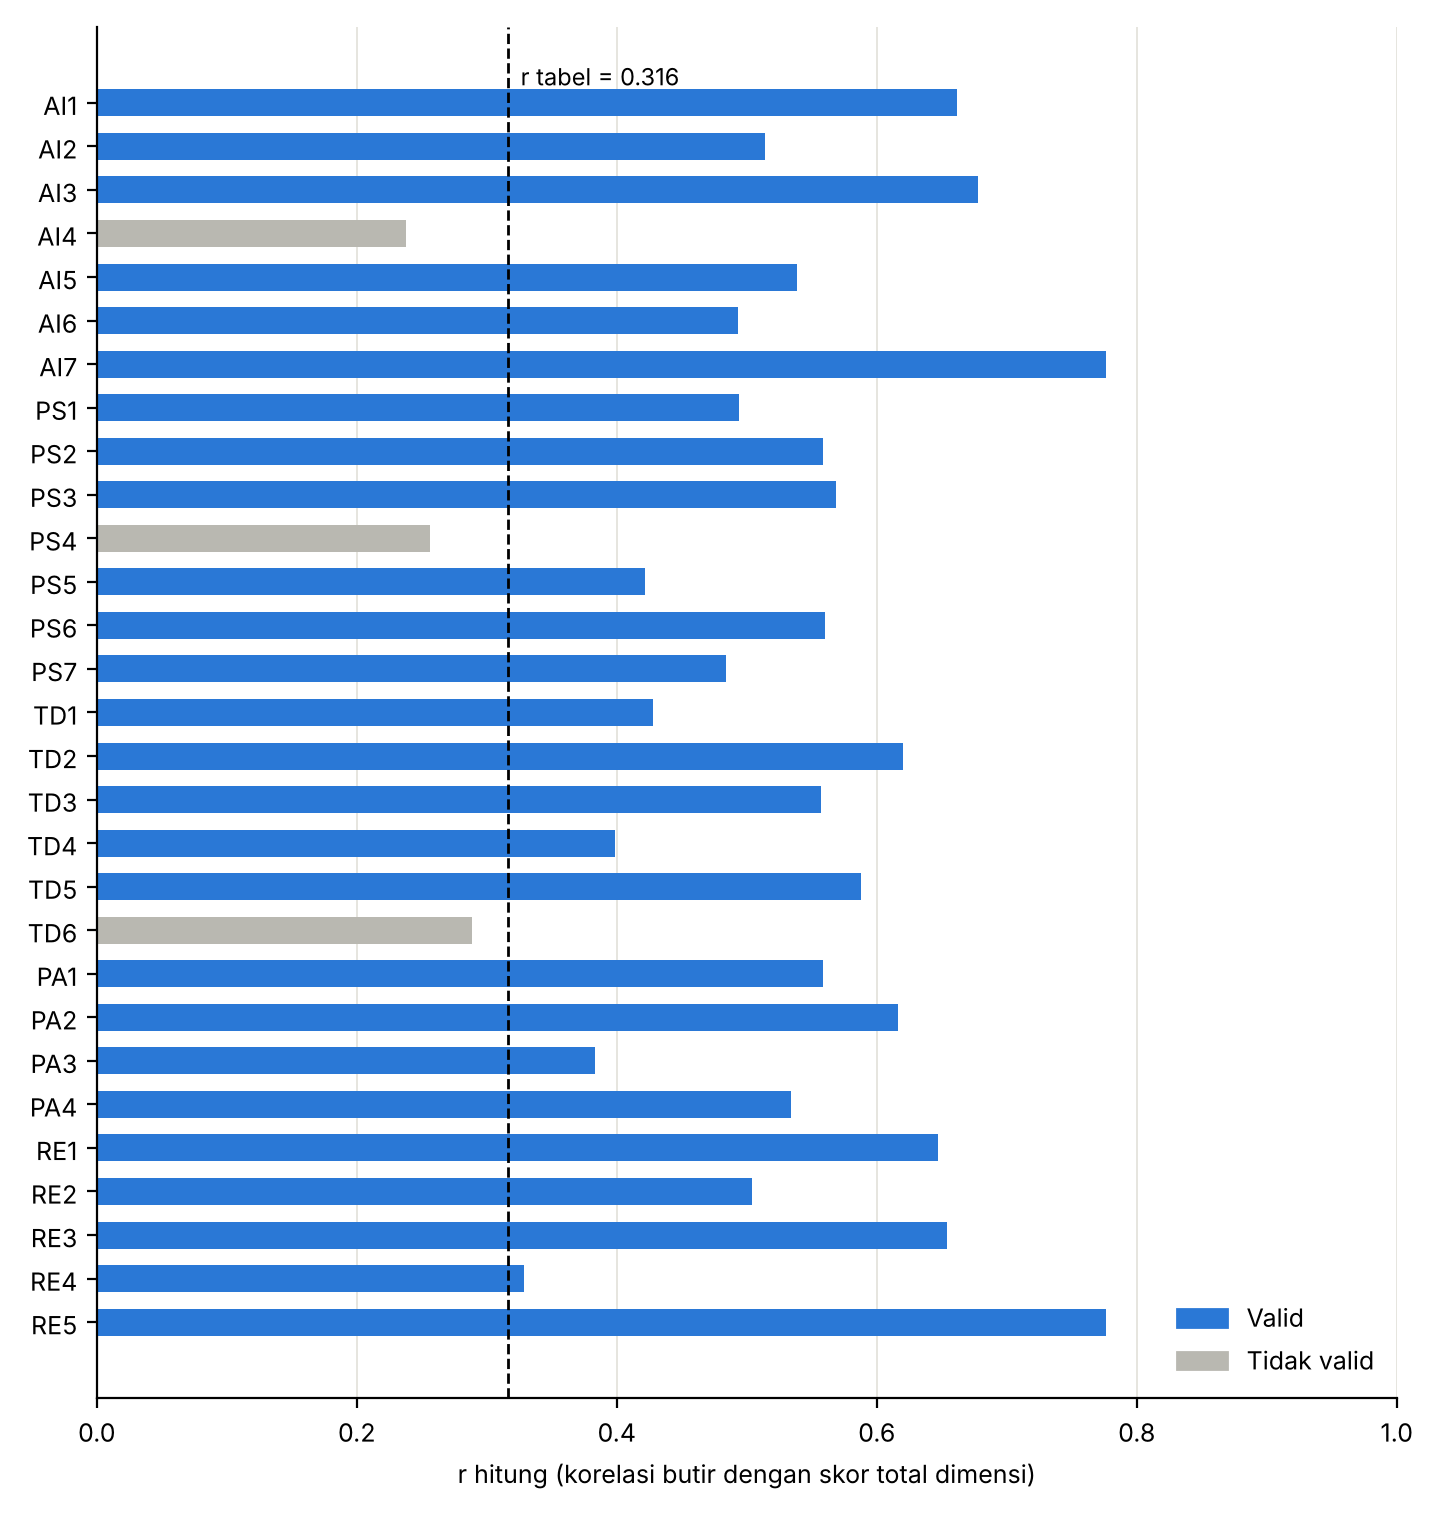

output/gambar_2_komposisi_AI.png


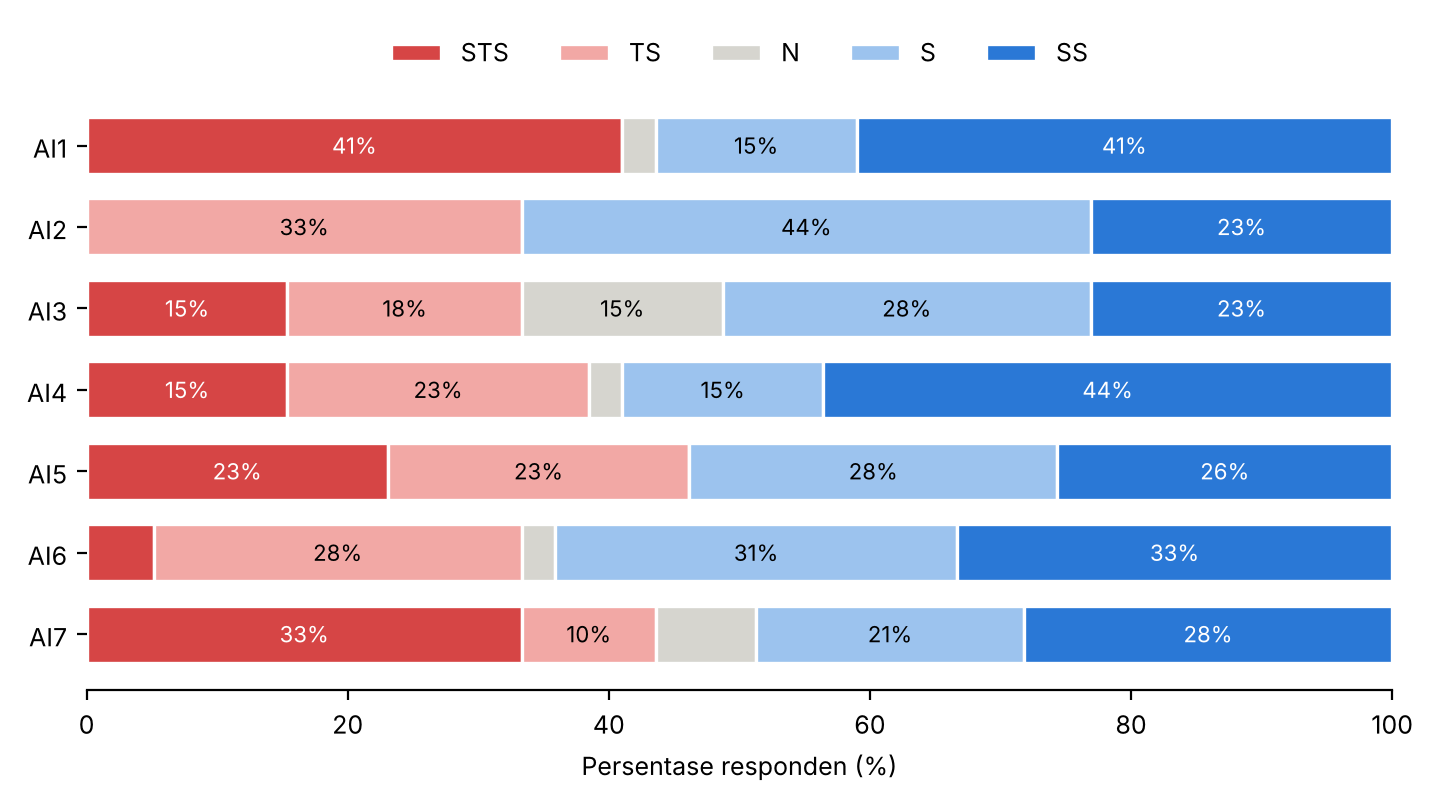

output/gambar_3_komposisi_PS.png


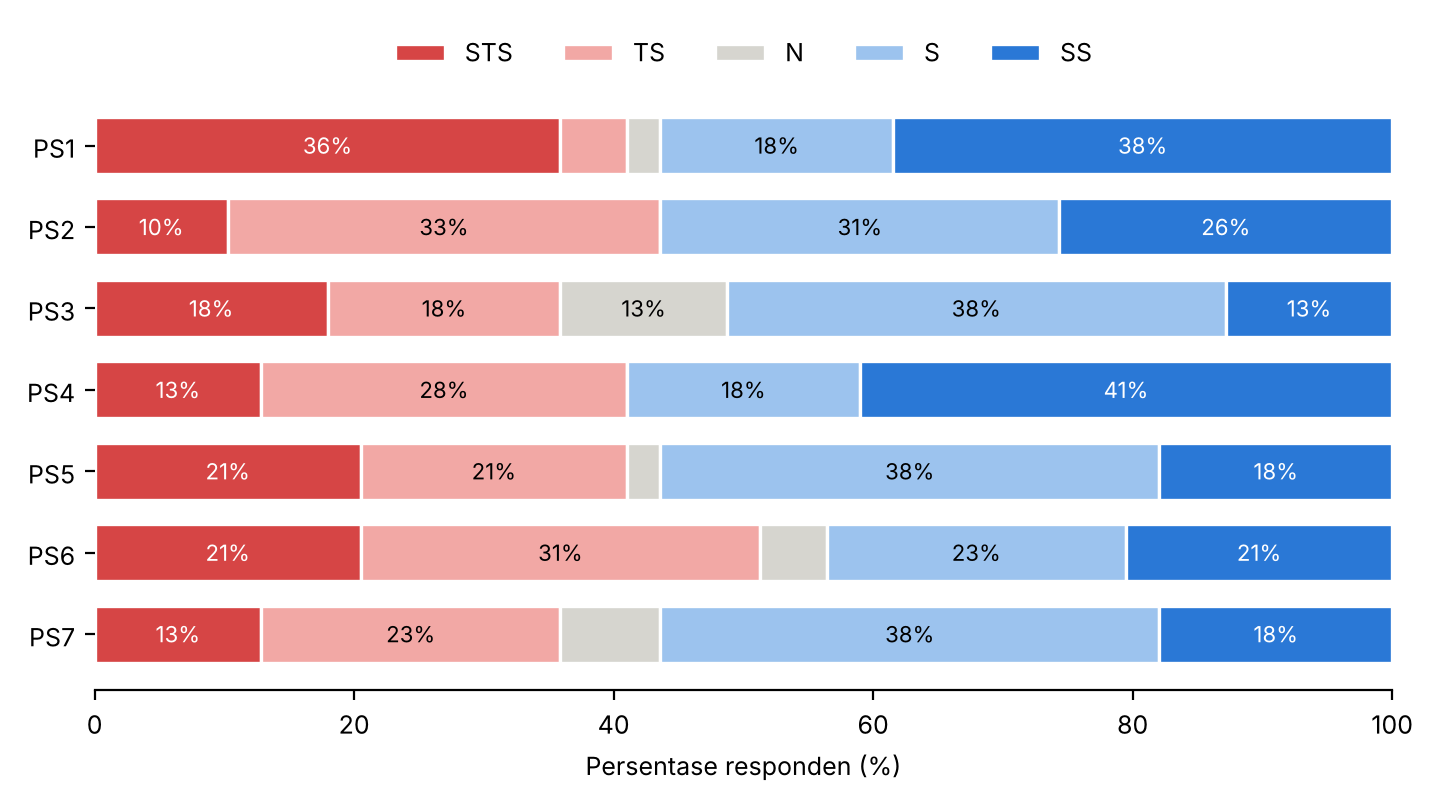

output/gambar_4_komposisi_TD.png


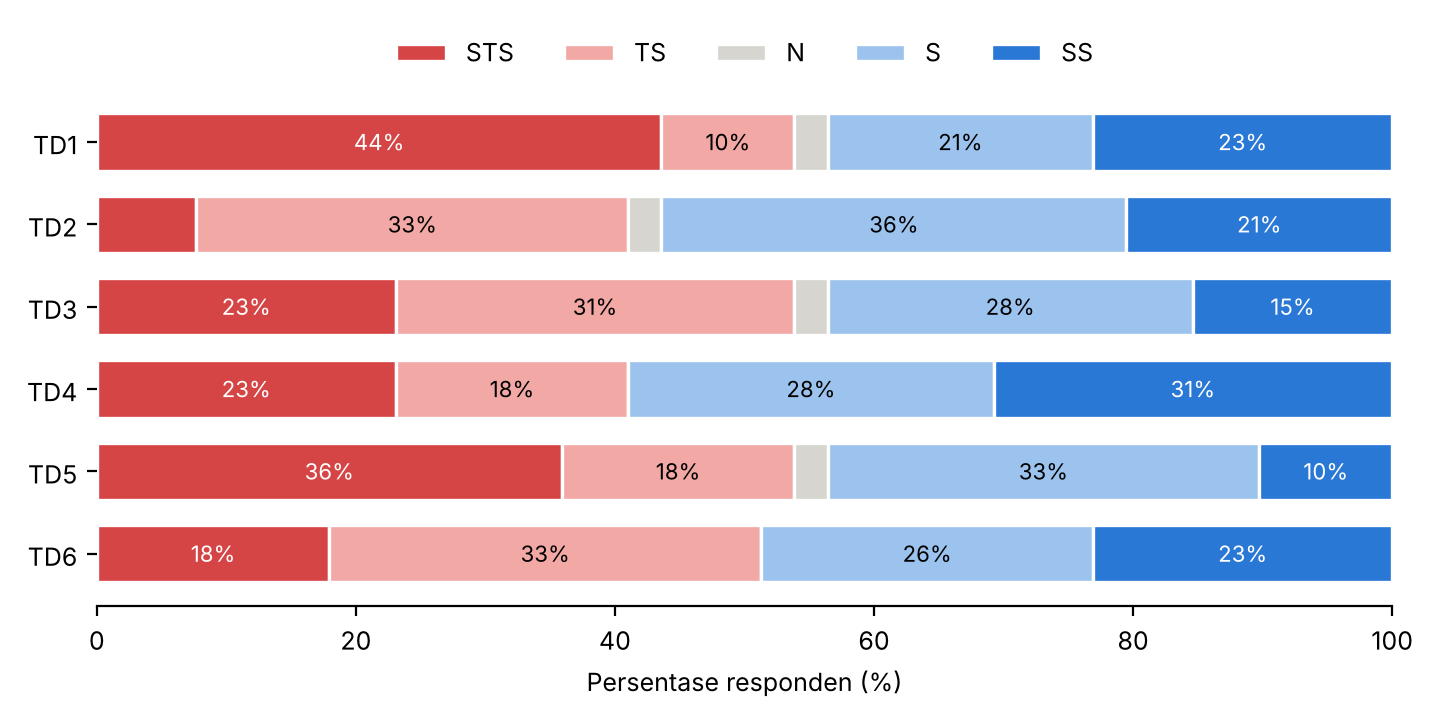

output/gambar_5_komposisi_PA.png


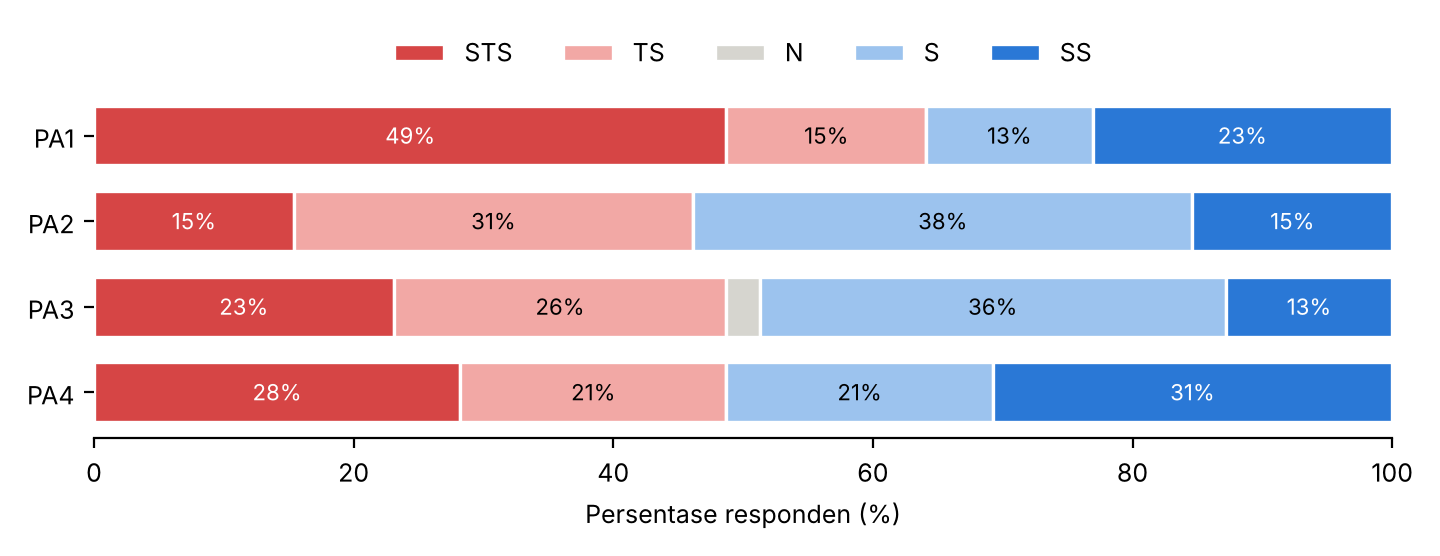

output/gambar_6_komposisi_RE.png


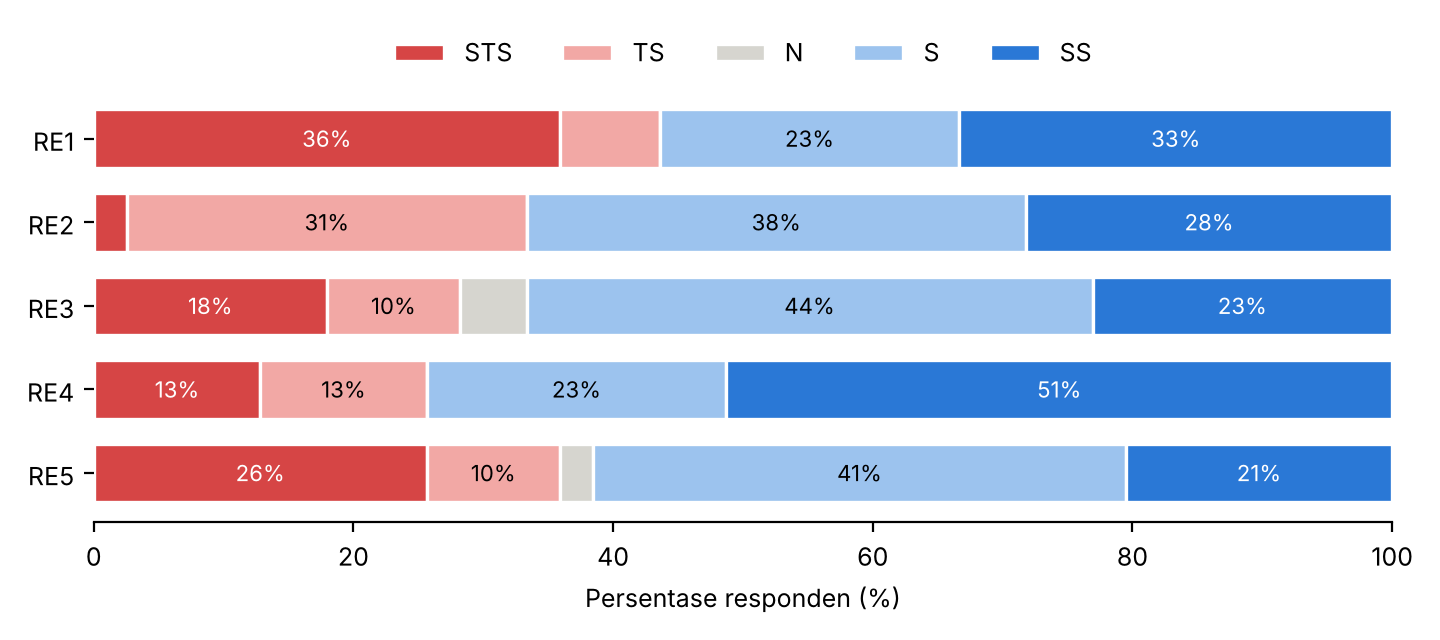

output/gambar_7_pola_jawaban.png


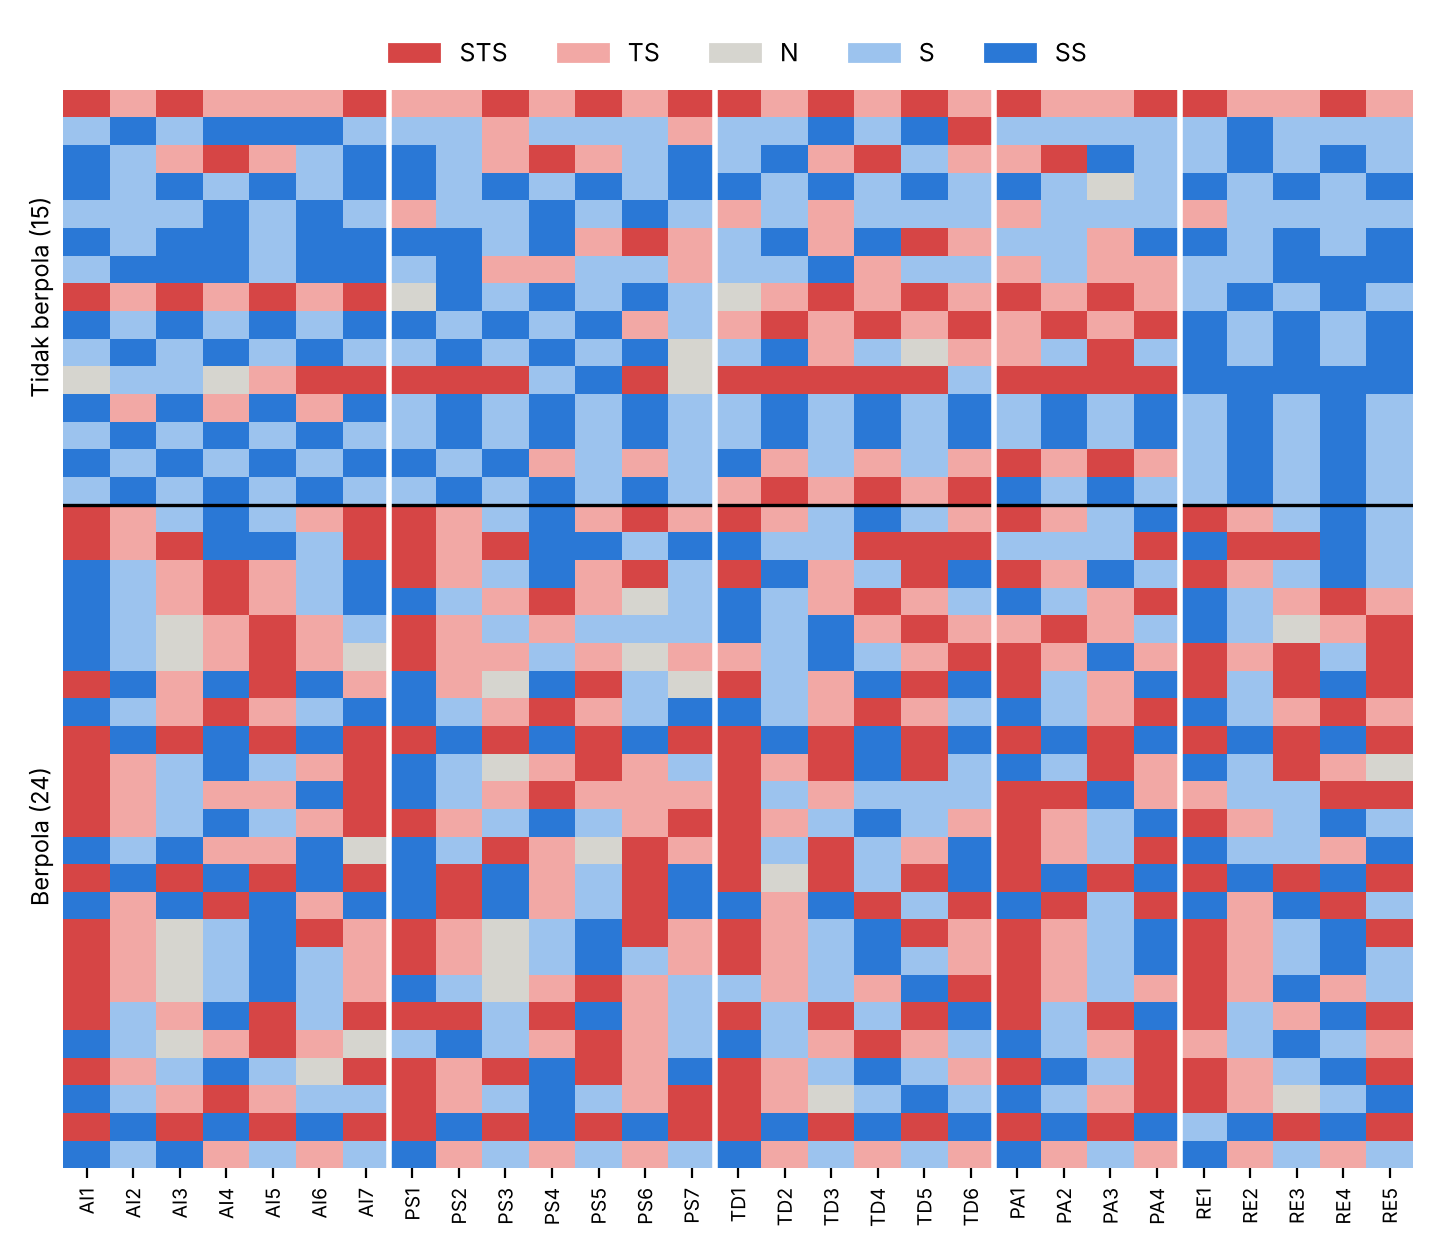

In [14]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob(f"{FOLDER_OUTPUT}/*.png")):
    print(f)
    display(Image(f, width=650))